# Coastal wave-video bathymetry: full active reconstruction

## Problem

This notebook reconstructs positive-up seabed elevation from **all native green-channel samples of two real recordings**, before loading any method result for comparison. The independent survey was acquired31July2020, one day before the1August2020 videos. Survey truth, reproduced native outputs and fresh local measurements have distinct roles. There is no optical measurement of wave height: intensity is a proxy for visible propagating patterns.

The selected single-date path uses analytic temporal signals, dynamic mode decomposition, robust local phase fitting, and robust wave-dispersion inversion. Multi-date Kalman filtering, optional RPCA and alternative EOF decompositions are outside this binding. The institutional author manuscript has a2January2023 running footer; it is distinguished from the2022 published article. Unsupported zero storage sentinels are masked grey, never plotted as measured zero depth.

In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,copy,importlib.util
os.environ.update(OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1')
ROOT=Path.cwd() if (Path.cwd()/'src').is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT));os.chdir(ROOT)
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from src.preprocessing import load_data,PARAMETERS,G
from src.physics_model import analytic_signal,dmd,gamma_from_bed,dispersion_wavenumber
from src.solvers import reconstruct,aggregate_wave_observations,fit_bed,fit_phase_plane
from src.visualization import observations_figure,mode_figure,wave_figure,bed_figure,point_map
s=importlib.util.spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(s);s.loader.exec_module(judge)
plt.rcParams.update({'figure.dpi':105,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
data=load_data();print('Interpreter:',sys.executable,'NumPy:',np.__version__);print({k:(v.shape,str(v.dtype)) for k,v in data.items()})


Interpreter: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy: 2.4.6
{'reconstruction_xy': ((8963, 2), 'float64'), 'signal_oblique': ((5075, 301), 'uint8'), 'time_oblique': ((301,), 'float64'), 'mode_xy_oblique': ((5075, 2), 'float64'), 'wave_xy_oblique': ((2479, 2), 'float64'), 'signal_planview': ((26382, 300), 'uint8'), 'time_planview': ((300,), 'float64'), 'mode_xy_planview': ((26382, 2), 'float64'), 'wave_xy_planview': ((7555, 2), 'float64')}


## 1. Data: all observations and legitimate geometry

The oblique record has5075 optical points and301 times; the planview has26382 optical points and300 times. Both span0to160s but their sample intervals differ. Counts are divided by255 without inventing a calibrated Gaussian noise variance. Separate M-grids, K-grids and the8963-site B-grid are fixed acquisition geometry. Geometry and water levels are available before inversion and were not fitted to the survey.

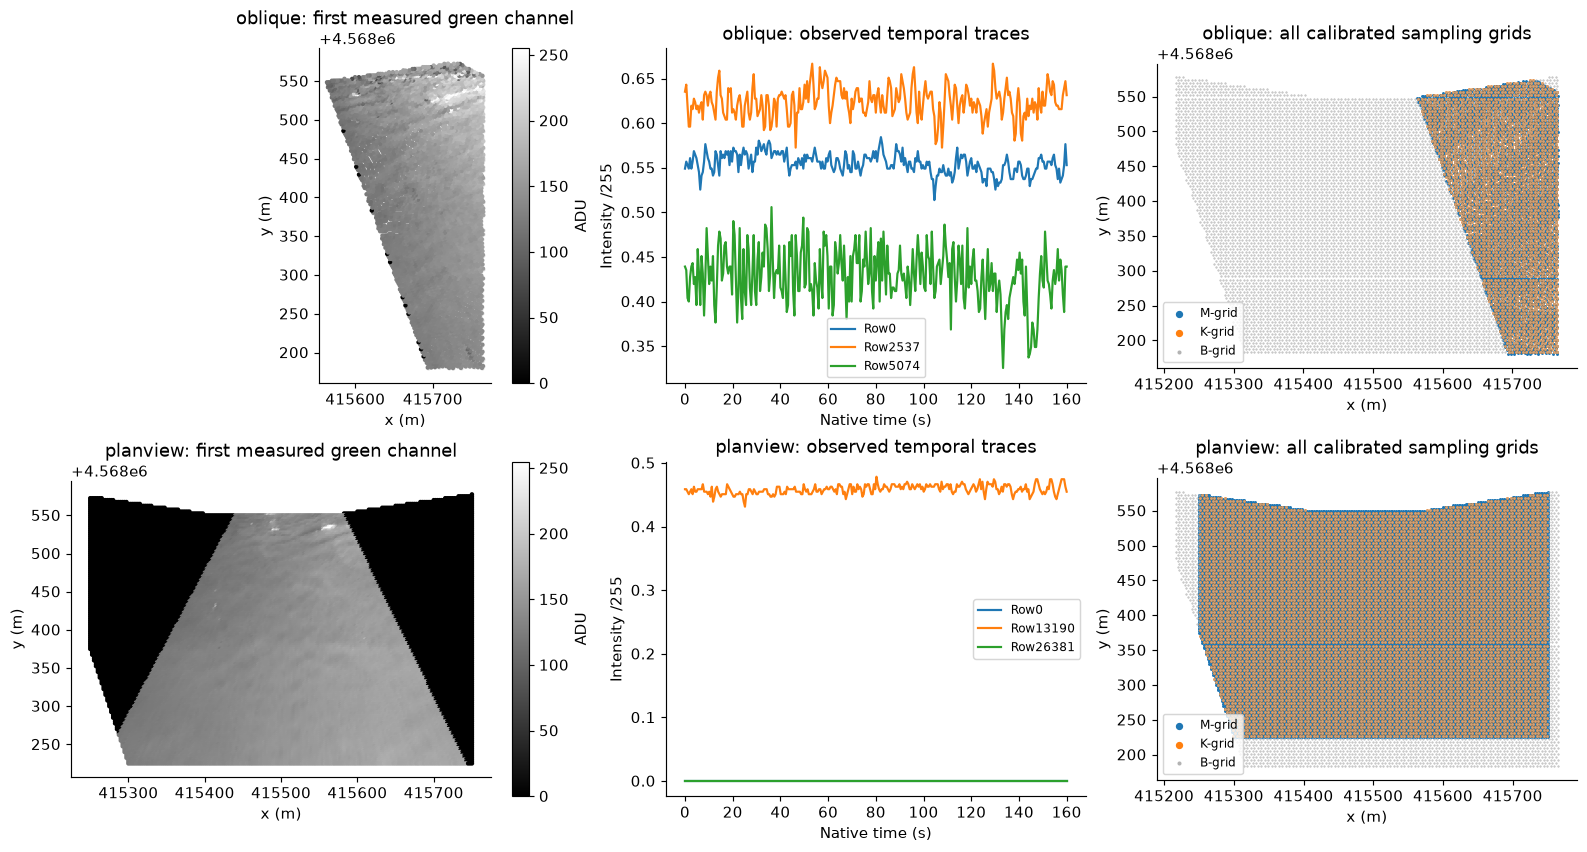

oblique samples= 301 dt= 0.5333333333333333 s
planview samples= 300 dt= 0.5351170568561873 s


In [2]:
observations_figure(data);plt.show()
for label in ['oblique','planview']:
    times=data['time_'+label];print(label,'samples=',len(times),'dt=',np.mean(np.diff(times)),'s')


## 2. Physics: fresh full-path recovery

For each retained narrow-band component, local phase gradients provide the wavenumber magnitude k. Linear gravity-wave dispersion connects angular frequency omega to water depth d and positive-up bed elevation z:

$$\omega^2=gk\tanh(kd),\qquad d=z_s-z>0,\qquad \gamma=\frac{\omega^2}{gk}.$$

Here g is gravitational acceleration, z_s is the known water-surface elevation of the recording, and gamma is dimensionless. There is no current/Doppler term. Robust phase-plane fitting handles optical outliers; multiple wavelength-scaled neighborhoods reduce dependence on a single spatial scale. Local dispersion fitting combines both recordings, each with its own water level.

The next cell actively executes every selected window, mode, wave neighborhood and B-grid site. It loads no cached phases or wavevectors. Runtime is measured, and the output is sent to the standalone survey/coverage evaluator.

In [3]:
started=time.perf_counter()
submission,diag=reconstruct(data,seed=20261026,return_diagnostics=True)
fresh_seconds=time.perf_counter()-started
Path('output').mkdir(exist_ok=True);np.savez_compressed('output/reconstruction.npz',**submission)
report=judge.evaluate('output/reconstruction.npz');print(json.dumps({'seconds':fresh_seconds,'stages':diag['timings'],'judge':report},indent=2,allow_nan=False));assert report['passed']
survey=np.load('evaluation/ground_truth.npz')['reconstruction'][0]
native=np.load('notebooks/reference_outputs/upstream.npz')
sequential_reference=np.load('notebooks/reference_outputs/sequential_upstream.npz')
with np.load('evaluation/baseline_reference.npz') as support:
    original_support=support['validity'][0].copy();required=support['interior_validity'][0].copy()
print('Fresh modes:',sum(len(r['modes']) for r in diag['records']),'Fresh qualified wave observations:',len(diag['observations']['gamma']))


oblique t00015.47_wt00060.00_T00005.05 wave_seconds 22.11
oblique t00015.47_wt00060.00_T00005.53 wave_seconds 22.285
oblique t00015.47_wt00060.00_T00006.67 wave_seconds 24.757
oblique t00015.47_wt00090.00_T00005.44 wave_seconds 22.185
oblique t00015.47_wt00090.00_T00005.46 wave_seconds 21.46
oblique t00015.47_wt00090.00_T00006.22 wave_seconds 23.393
oblique t00045.33_wt00060.00_T00005.37 wave_seconds 21.572
oblique t00045.33_wt00060.00_T00006.01 wave_seconds 23.061
oblique t00045.33_wt00060.00_T00006.60 wave_seconds 24.659
oblique t00045.33_wt00090.00_T00005.38 wave_seconds 22.032
oblique t00045.33_wt00090.00_T00005.95 wave_seconds 22.941
oblique t00045.33_wt00090.00_T00008.86 wave_seconds 29.405
planview t00015.52_wt00060.00_T00005.65 wave_seconds 56.143
planview t00015.52_wt00060.00_T00008.38 wave_seconds 91.859
planview t00015.52_wt00090.00_T00005.56 wave_seconds 55.422
planview t00015.52_wt00090.00_T00006.56 wave_seconds 66.214
planview t00045.48_wt00060.00_T00005.51 wave_seconds 5

## 3. Method: fresh temporal modes and source comparison

The analytic signal uses an explicit one-sided FFT multiplier. Hilbert extension protects window edges; the selected DMD truncation separates coherent oscillations. For consecutive complex snapshot matrices X0 and X1, truncate their singular-value decomposition to rank6:

$$X_0=USV^*,\qquad \widetilde A=U^*X_1VS^{-1},\qquad \widetilde A Y=Y\Lambda,\qquad \Phi=X_1VS^{-1}Y.$$

Here U and V contain retained singular vectors, S contains singular values, Y contains reduced eigenvectors, Lambda contains eigenvalues eta, and columns of Phi are spatial modes. A star denotes conjugate transpose. The period is T=2pi*dt/Im(log(eta)), where dt is the record's actual sample interval; retain3.5to15s. Spatial phases have an arbitrary global origin, so phase differences are compared with that gauge accounted for. All retained modes are shown; these are fresh numerical measurements, not the paper's historical mode figures.

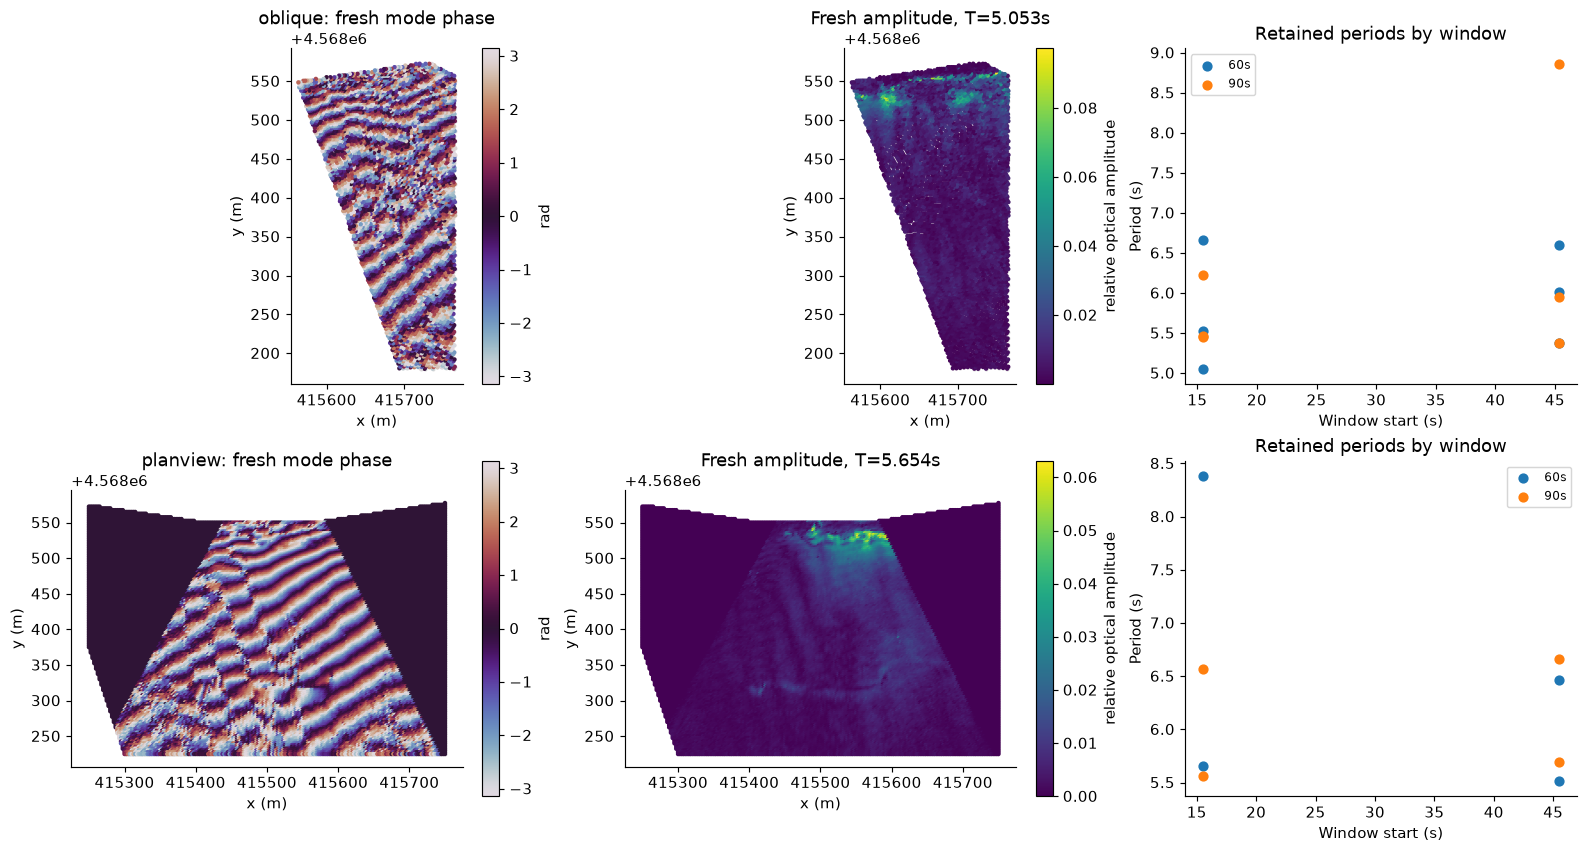

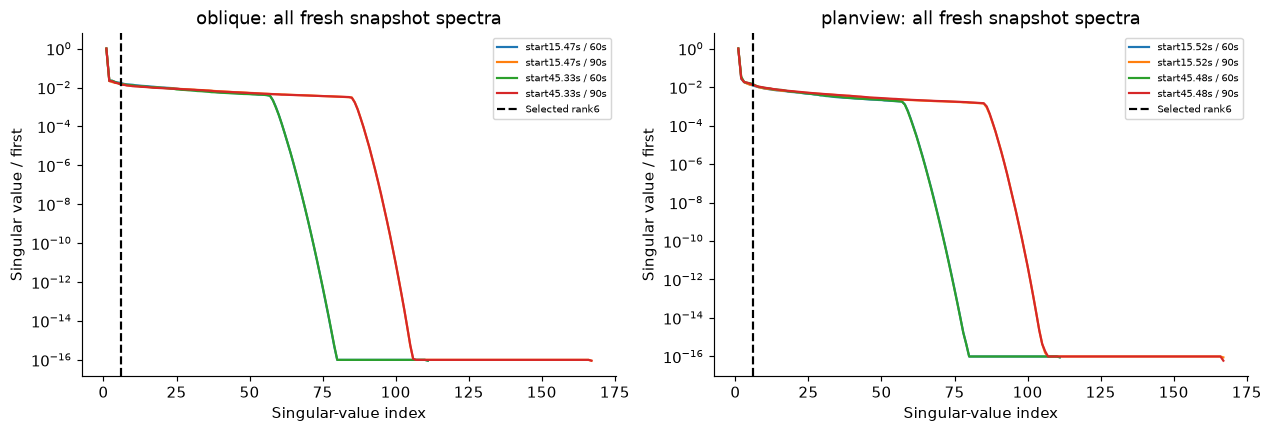

label,window_s,fresh_count,original_count,max_period_difference_s: [('oblique', 60, 6, 6, 8.881784197001252e-15), ('oblique', 90, 6, 6, 1.0125233984581428e-13), ('planview', 60, 4, 4, 1.0658141036401503e-14), ('planview', 90, 4, 4, 4.440892098500626e-15)]
Every retained mode vs independently captured original: [
  {
    "record": "oblique",
    "key": "t00015.47_wt00060.00_T00005.05",
    "period_error_s": 3.552713678800501e-15,
    "phase_gauge_rms_rad": 2.2310268959220272e-13,
    "amplitude_relative_l2": 1.172478208315685e-14
  },
  {
    "record": "oblique",
    "key": "t00015.47_wt00060.00_T00005.53",
    "period_error_s": 2.6645352591003757e-15,
    "phase_gauge_rms_rad": 5.144670590949194e-14,
    "amplitude_relative_l2": 1.065387922017321e-14
  },
  {
    "record": "oblique",
    "key": "t00015.47_wt00060.00_T00006.67",
    "period_error_s": 4.440892098500626e-15,
    "phase_gauge_rms_rad": 2.564194746596902e-14,
    "amplitude_relative_l2": 5.509565008501497e-15
  },
  {
    "

In [4]:
mode_figure(diag['records']);plt.show()
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax,record in zip(axs,diag['records']):
    for spectrum in record['spectra']:
        singular=spectrum['singular_values'];ax.semilogy(np.arange(1,len(singular)+1),singular/singular[0],label=f"start{spectrum['start_seconds']:.2f}s / {spectrum['window_seconds']:.0f}s")
    ax.axvline(PARAMETERS['rank'],color='k',ls='--',label='Selected rank6');ax.set(title=record['label']+': all fresh snapshot spectra',xlabel='Singular-value index',ylabel='Singular value / first');ax.legend(fontsize=7)
plt.show()
stage=np.load('test/fixtures/upstream_stages.npz')
period_rows=[]
for record in diag['records']:
    for window in [60,90]:
        fresh=np.sort([m['period'] for m in record['modes'] if m['window_seconds']==window])
        original=[]
        for start in [0,56]:
            values=stage[f"output_period_{record['label']}_{start}_{window}"]
            original.extend(values[np.isfinite(values)&(values>=PARAMETERS['min_period'])&(values<=PARAMETERS['max_period'])])
        original=np.sort(original)
        period_rows.append((record['label'],window,len(fresh),len(original),float(np.max(abs(fresh-original))) if len(fresh)==len(original) else None))
print('label,window_s,fresh_count,original_count,max_period_difference_s:',period_rows)
parity_details=[]
for record in diag['records']:
    for mode in record['modes']:
        extension=int(PARAMETERS['max_period']/record['dt'])+1
        start=min([0,56],key=lambda i:abs(record['time'][i+extension]-mode['start_seconds']))
        window=int(mode['window_seconds']);prefix=f"{record['label']}_{start}_{window}"
        original_period=stage['output_period_'+prefix];j=int(np.argmin(np.where(np.isfinite(original_period),abs(original_period-mode['period']),np.inf)))
        original_phase=stage['output_phase_'+prefix][j];original_amplitude=stage['output_amplitude_'+prefix][j]
        phase_delta=np.angle(np.exp(1j*(mode['phases']-original_phase)));gauge=np.angle(np.mean(np.exp(1j*phase_delta)))
        gauge_rms=float(np.sqrt(np.mean(np.angle(np.exp(1j*(phase_delta-gauge)))**2)))
        amplitude_error=float(np.linalg.norm(mode['amplitudes']-original_amplitude)/np.linalg.norm(original_amplitude))
        parity_details.append({'record':record['label'],'key':mode['key'],'period_error_s':float(abs(mode['period']-original_period[j])),'phase_gauge_rms_rad':gauge_rms,'amplitude_relative_l2':amplitude_error})
print('Every retained mode vs independently captured original:',json.dumps(parity_details,indent=2))


## 4. Wave fields, quality filters and support

Wavenumber is the magnitude of the fitted phase gradient, not an assumed propagation direction. Relative to the closest observed point, fit the principal phase difference by

$$\operatorname{arg}\exp(i(\phi-\phi_0))\simeq k_x\Delta x+k_y\Delta y+c,\qquad k=\sqrt{k_x^2+k_y^2}.$$

Here phi and phi0 are modal phases in radians, Delta x and Delta y are calibrated displacements in m, c is an intercept, and kx/ky are fitted gradient components in rad/m. RANSAC finds a phase-consistent subset and refits it. Three radii follow the frequency-dependent wavelengths at declared trial depths. Gamma, its local mean and local standard deviation provide observation-based quality tests. Grey locations have no accepted estimate. These masks never inspect the survey error. The local gamma standard deviation is a spatial-consistency diagnostic, not a posterior uncertainty.

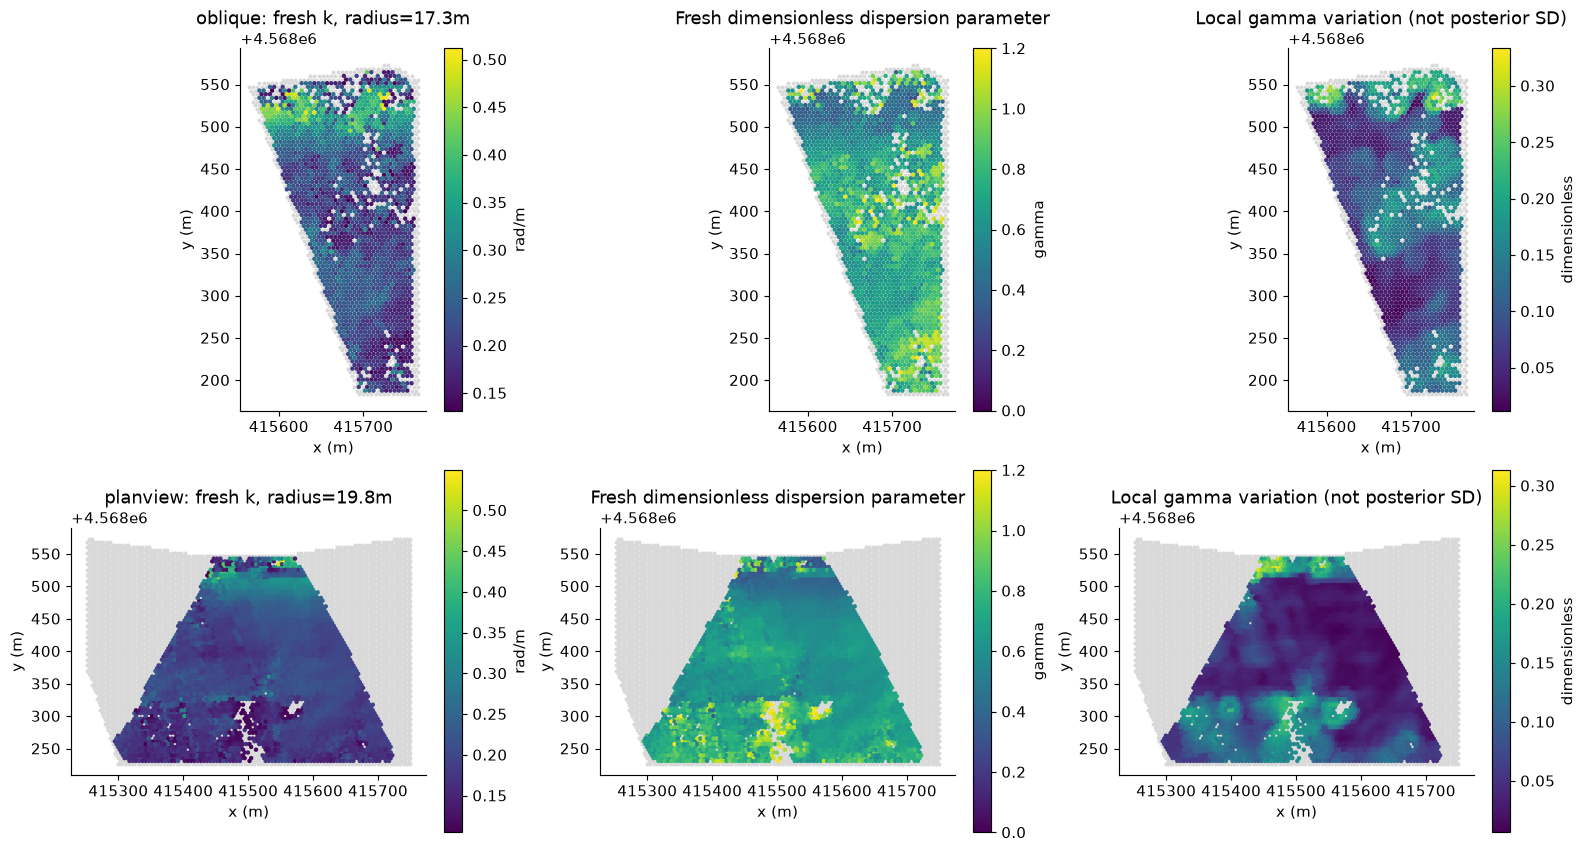

In [5]:
wave_figure(diag['wave_fields']);plt.show()


## 5. Results: independent survey, native result, fresh result and complete coverage

Survey and both reconstructions share the physical vertical datum. No fitted offset, rescaling or spatial shift is applied. Maps retain every output location. The original-only frozen policy requires at least98% recall of the full5615-site original wave-support footprint and100% coverage of its4410-site interior more than20m from original invalid sites. Physical elevation errors are scored on that interior and on all submitted valid sites, each using its own survey dynamic range. Unsupported zero sentinels enter coverage, never physical depth errors. These rules were fixed from independent original-code repeats before local full-field judgement. The one-day survey/video separation and changing morphology limit physical accuracy interpretation.

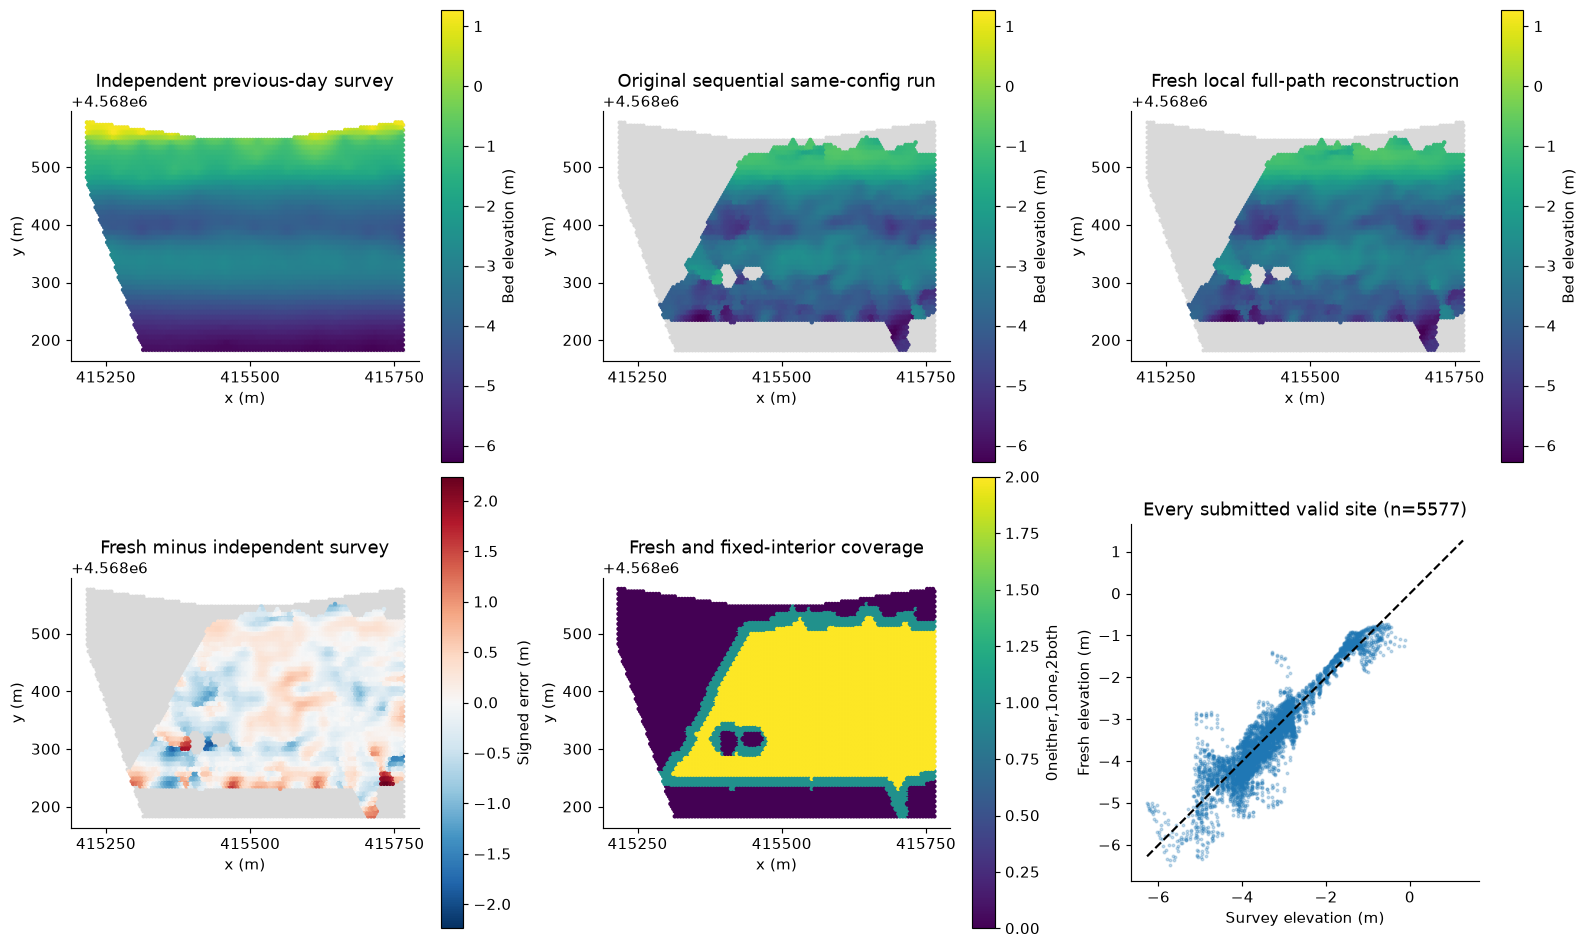

Reference roles: independent survey truth; reproduced native method; fresh cleaned local method.
Original first (archived) own valid footprint: sites= 5615 cosine NCC= 0.9926581740375783 dynamic-range NRMSE= 0.06947820996167868
Original first (archived) same fixed interior: sites= 4410 interior coverage= 1.0 original-support recall= 1.0 interior NCC= 0.9950154629160846 interior NRMSE= 0.08072550183769538
Original sequential same-config own valid footprint: sites= 5580 cosine NCC= 0.9930317097740343 dynamic-range NRMSE= 0.06769220391401265
Original sequential same-config same fixed interior: sites= 4410 interior coverage= 1.0 original-support recall= 0.98753339269813 interior NCC= 0.9950781980276602 interior NRMSE= 0.08024297063388498
Fresh sequential local own valid footprint: sites= 5577 cosine NCC= 0.9930284204194217 dynamic-range NRMSE= 0.067696538411297
Fresh sequential local same fixed interior: sites= 4410 interior coverage= 1.0 original-support recall= 0.9877114870881567 interio

In [2]:
from matplotlib.ticker import MaxNLocator
bed_display_figure=bed_figure(data['reconstruction_xy'],submission,survey,sequential_reference,required)
for bed_map_axis in bed_display_figure.axes[:5]:
    bed_map_axis.xaxis.set_major_locator(MaxNLocator(nbins=3))
plt.show()
valid=submission['validity'][0];bed=submission['reconstruction'][0]
print('Reference roles: independent survey truth; reproduced native method; fresh cleaned local method.')
for name,values,mask in [('Original first (archived)',native['bed'],native['validity']),('Original sequential same-config',sequential_reference['bed'],sequential_reference['validity']),('Fresh sequential local',bed,valid)]:
    ncc,nrmse=judge.score(values[mask],survey[mask]);print(name,'own valid footprint: sites=',mask.sum(),'cosine NCC=',ncc,'dynamic-range NRMSE=',nrmse)
    assert np.all(mask[required]),'Cannot compare a fixed-interior depth metric with missing elevations'
    fixed_ncc,fixed_nrmse=judge.score(values[required],survey[required])
    print(name,'same fixed interior: sites=',required.sum(),'interior coverage=',np.mean(mask[required]),'original-support recall=',np.mean(mask[original_support]),'interior NCC=',fixed_ncc,'interior NRMSE=',fixed_nrmse)
np.testing.assert_allclose(judge.score(np.array([1.,2.,3.]),np.array([1.,2.,3.])),[1.,0.],atol=1e-15)
same_config_common=valid&sequential_reference['validity']
print('Fresh vs independent same-config source: common sites=',same_config_common.sum(),'support disagreements=',np.count_nonzero(valid!=sequential_reference['validity']),'common bed RMS difference(m)=',np.sqrt(np.mean((bed[same_config_common]-sequential_reference['bed'][same_config_common])**2)))


## 5b. Original-code stochastic repeat and preserved local failure

The source-variability panels come from independently executed original-code runs on the exact same optical acquisition. They are archived reproduced results, not fresh local fits. RANSAC variability changes some boundary support and local depths. Their common-support difference is not a confidence interval, and their local spatial SD is not a posterior standard error. Final required coverage is fixed from original-only observation-support evidence before judging the local full-field result; all additionally supplied valid sites remain survey-scored.

The last panel preserves the earlier **FAILED local proposal-prefetch implementation**, which missed one fixed interior point. It is neither an original-code result nor the fresh sequential-method reconstruction. The repair restores the original sequential RandomState sampling stream with unchanged seed and parameters; no seed search, point filling or threshold change was used. The independent32-call stream audit and new original full-field qualification are recorded in validation.

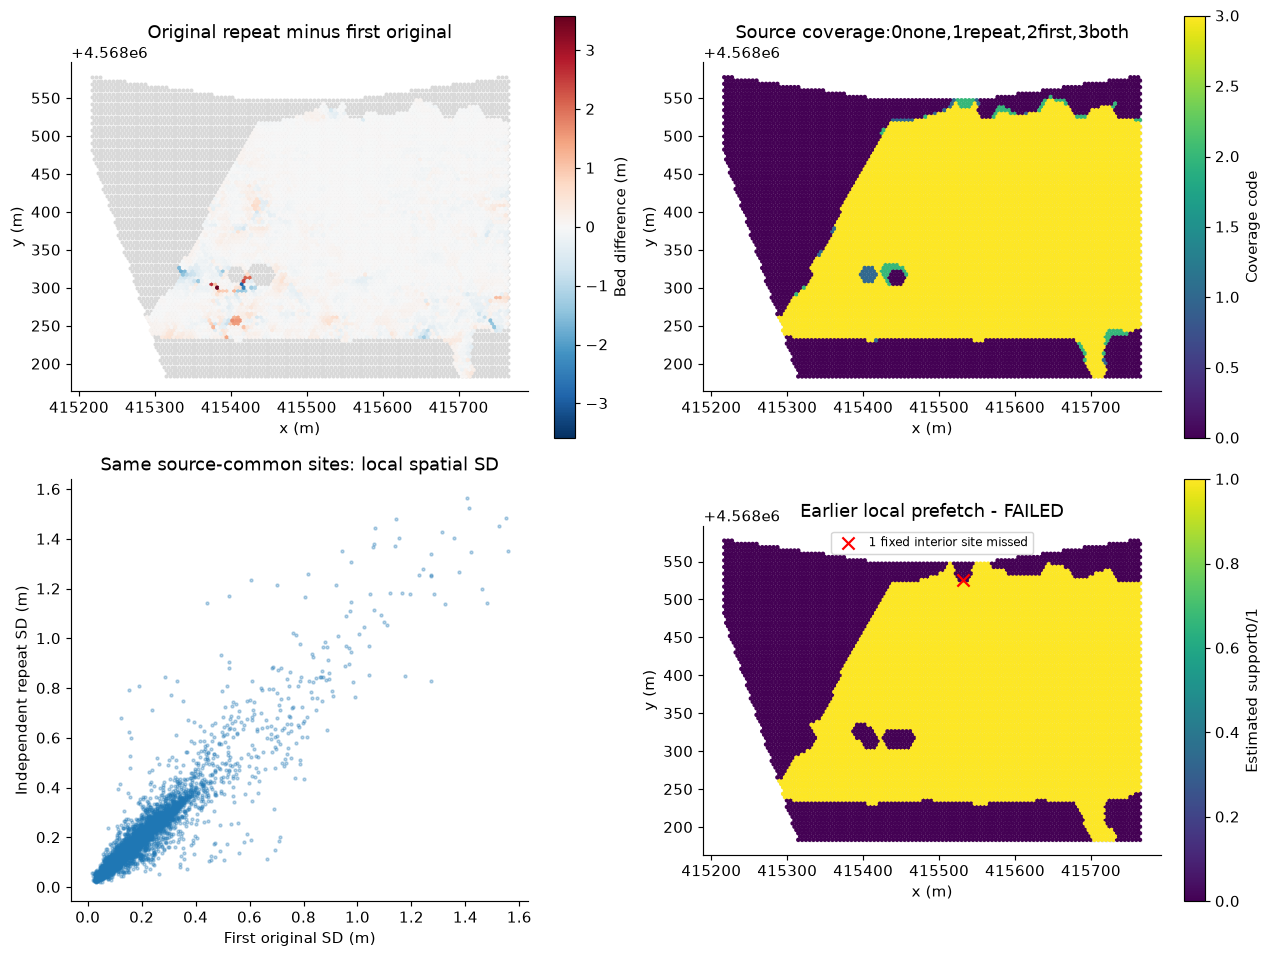

Earlier failed local result, retained NOT fresh: {'all_valid_ncc': 0.9933248338451487, 'all_valid_nrmse': 0.06773502986743632, 'required_coverage': 0.9814781834372217, 'interior_coverage': 0.9997732426303855} status= fail
Original-only repeat: first/repeat/common valid counts: 5615 5572 5532 common depth RMS difference(m)= 0.17968996705621942
Original first own-valid NCC/NRMSE= (0.9926581740375783, 0.06947820996167868) same fixed interior NCC/NRMSE= (0.9950154629160846, 0.08072550183769538) interior coverage= 1.0 original-support recall= 1.0
Original repeat own-valid NCC/NRMSE= (0.992728150142737, 0.07062761020548652) same fixed interior NCC/NRMSE= (0.9951610814578649, 0.07919450463895528) interior coverage= 1.0 original-support recall= 0.9852181656277827


In [7]:
repeat_bed=native['repeat_bed'];repeat_valid=native['repeat_validity'];repeat_sd=native['repeat_standard_deviation']
first_valid=native['validity'];source_common=first_valid&repeat_valid;delta=repeat_bed-native['bed'];xy=data['reconstruction_xy']
fig,axs=plt.subplots(2,2,figsize=(12,9),layout='constrained');axs=axs.ravel()
point_map(axs[0],xy,delta,'Original repeat minus first original','Bed difference (m)',valid=source_common,cmap='RdBu_r',symmetric=True)
coverage_code=2*first_valid.astype(int)+repeat_valid.astype(int)
point_map(axs[1],xy,coverage_code,'Source coverage:0none,1repeat,2first,3both','Coverage code',limits=(0,3))
common_sd=source_common&np.isfinite(native['standard_deviation'])&np.isfinite(repeat_sd)
axs[2].scatter(native['standard_deviation'][common_sd],repeat_sd[common_sd],s=4,alpha=.3);axs[2].set(title='Same source-common sites: local spatial SD',xlabel='First original SD (m)',ylabel='Independent repeat SD (m)')
failed_prefetch=np.load('notebooks/reference_outputs/failed_prefetch_local.npz');failed_valid=failed_prefetch['validity'][0]
point_map(axs[3],xy,failed_valid.astype(float),'Earlier local prefetch - FAILED','Estimated support0/1',limits=(0,1))
missed=required&~failed_valid;axs[3].scatter(xy[missed,0],xy[missed,1],s=70,marker='x',color='red',label=f'{missed.sum()} fixed interior site missed');axs[3].legend(fontsize=8);plt.show()
failed_report=judge.evaluate('notebooks/reference_outputs/failed_prefetch_local.npz');print('Earlier failed local result, retained NOT fresh:',{k:failed_report['metrics'][k] for k in ['all_valid_ncc','all_valid_nrmse','required_coverage','interior_coverage']},'status=',failed_report['status'])
print('Original-only repeat: first/repeat/common valid counts:',first_valid.sum(),repeat_valid.sum(),source_common.sum(),'common depth RMS difference(m)=',np.sqrt(np.mean(delta[source_common]**2)))
for name,values,mask in [('Original first',native['bed'],first_valid),('Original repeat',repeat_bed,repeat_valid)]:
    own=judge.score(values[mask],survey[mask]);assert np.all(mask[required]);fixed=judge.score(values[required],survey[required])
    print(name,'own-valid NCC/NRMSE=',own,'same fixed interior NCC/NRMSE=',fixed,'interior coverage=',np.mean(mask[required]),'original-support recall=',np.mean(mask[original_support]))


## 6. Actual residuals and spatial variation diagnostic

Dispersion residuals are dimensionless gamma discrepancies on the fitted local consensus. For observation j, predicted wavenumber kprime is obtained from the recorded frequency and positive depth zs-z. The scalar bed refit minimizes

$$\varepsilon_j(z)=\gamma_j-\frac{\omega_j^2}{gk'_j(z)},\qquad \min_z\sqrt{\frac1N\sum_{j\in C}\varepsilon_j(z)^2}.$$

Here C is the fixed local robust consensus, N is its size, z is positive-up bed elevation, and the remaining quantities are defined above. The reported bed standard deviation is the native local spatial standard deviation of estimated neighboring elevations; it is not calibrated posterior error or a confidence interval. Both are displayed with their actual supported-point counts, alongside the independent measured survey discrepancy.

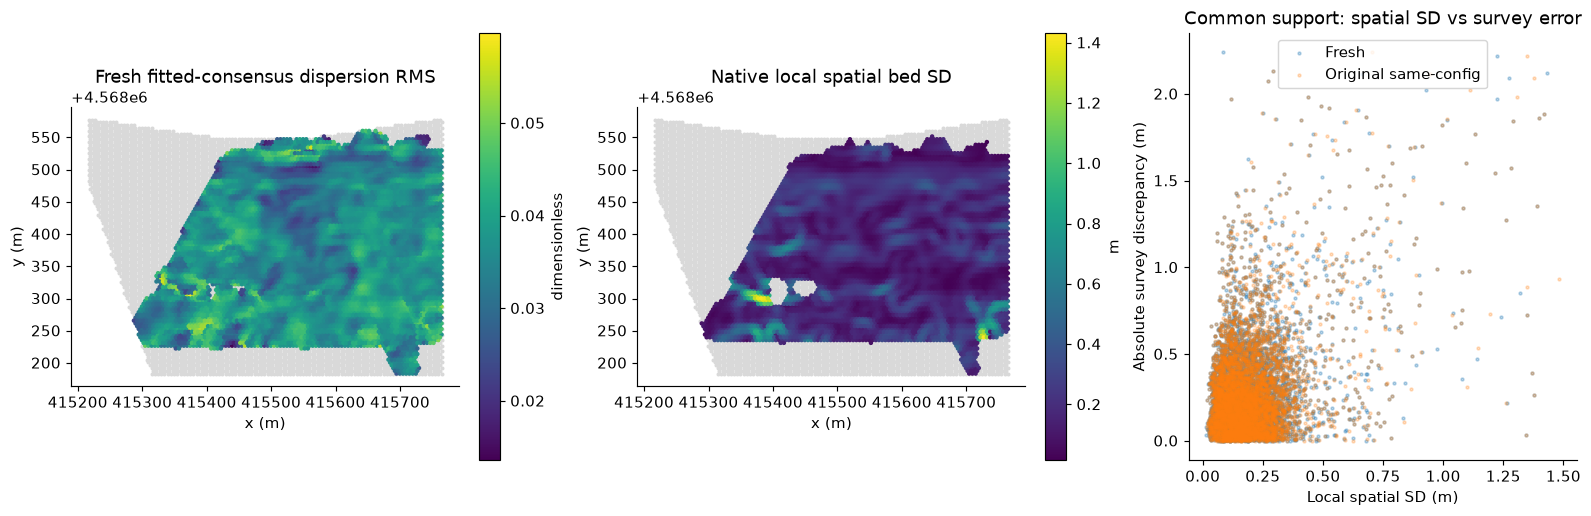

Residual finite sites: 6174 submitted valid: 5577
Native-convention BFGS success flags: 6174 of 6174 raw estimates; a returned estimate is not an assertion that every optimizer reported convergence.


In [8]:
bdiag=diag['bed'];xy=data['reconstruction_xy']
fig,axs=plt.subplots(1,3,figsize=(15,4.8),layout='constrained')
point_map(axs[0],xy,bdiag['gamma_rmse'],'Fresh fitted-consensus dispersion RMS','dimensionless')
point_map(axs[1],xy,bdiag['uncertainty'],'Native local spatial bed SD','m')
good=valid&sequential_reference['validity']&np.isfinite(bdiag['uncertainty'])&np.isfinite(sequential_reference['standard_deviation']);axs[2].scatter(bdiag['uncertainty'][good],abs(bed[good]-survey[good]),s=4,alpha=.3,label='Fresh')
axs[2].scatter(sequential_reference['standard_deviation'][good],abs(sequential_reference['bed'][good]-survey[good]),s=4,alpha=.25,label='Original same-config');axs[2].set(title='Common support: spatial SD vs survey error',xlabel='Local spatial SD (m)',ylabel='Absolute survey discrepancy (m)');axs[2].legend();plt.show()
print('Residual finite sites:',np.isfinite(bdiag['gamma_rmse']).sum(),'submitted valid:',valid.sum())
print('Native-convention BFGS success flags:',int(bdiag['optimizer_success'].sum()),'of',int(np.isfinite(bdiag['raw_bed']).sum()),'raw estimates; a returned estimate is not an assertion that every optimizer reported convergence.')


## 7. Four actual phase-neighborhood robustness comparisons

Four neighborhoods were fixed during original-only qualification before local extraction. Their64 original RANSAC repeats form comparison distributions, not seed-matched targets. The current solver is run64 times on those same actual observed phase-neighborhood probes using independent seeds, then on controlled0.03rad and0.10rad additional phase perturbations. These are small-stage robustness experiments, separate from the complete fresh primary inversion above.

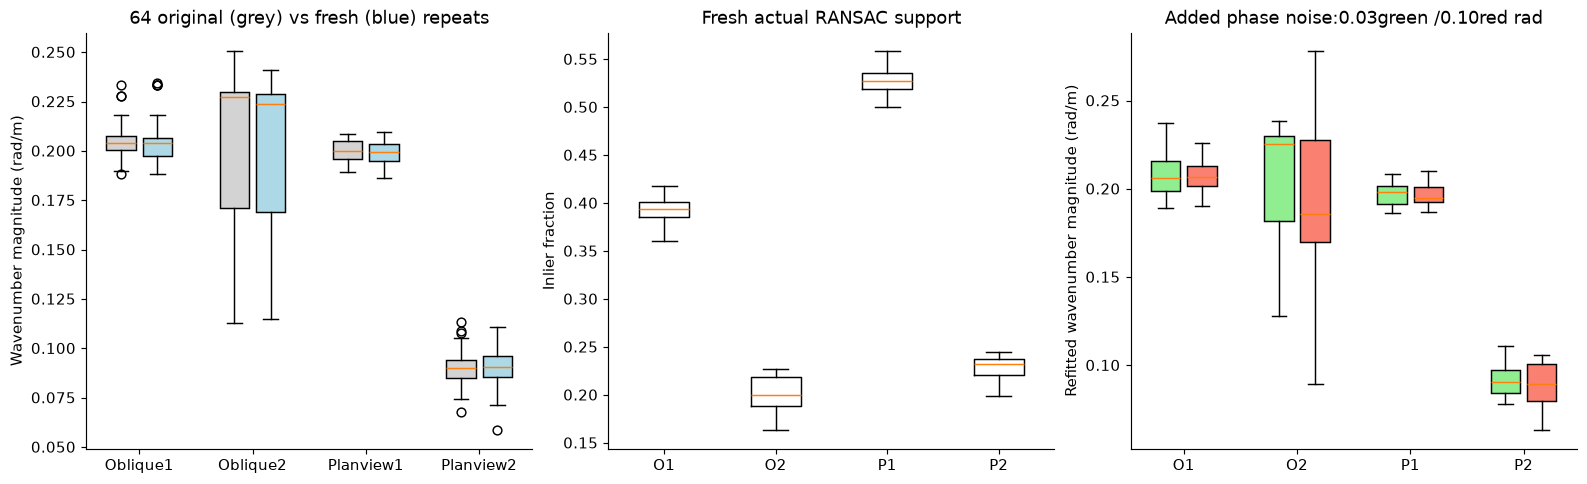

In [9]:
fixture=np.load('test/fixtures/upstream_ransac_statistics.npz')
native_k=[];fresh_k=[];noise_k={.03:[],.10:[]};inlier=[]
for case in range(4):
    x,y,phase=[fixture[f'input_{v}_{case}'] for v in ['x','y','phase']]
    native_k.append(np.linalg.norm(fixture[f'output_coefficients_{case}'][:,:2],axis=1));ks=[];counts=[]
    for repeat in range(64):
        coefficient,ids,statistics=fit_phase_plane(x,y,phase,np.random.RandomState(30000+repeat))
        ks.append(np.linalg.norm(coefficient[:2]));counts.append(len(ids)/len(x))
    fresh_k.append(ks);inlier.append(counts)
    for sigma in noise_k:
        vals=[]
        for repeat in range(32):
            rng=np.random.RandomState(40000+repeat);perturbed=np.angle(np.exp(1j*(phase+rng.normal(0,sigma,len(phase)))));coefficient,ids,statistics=fit_phase_plane(x,y,perturbed,rng);vals.append(np.linalg.norm(coefficient[:2]))
        noise_k[sigma].append(vals)
fig,axs=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
positions=np.arange(4)
axs[0].boxplot(native_k,positions=positions-.16,widths=.26,patch_artist=True,boxprops={'facecolor':'lightgray'},manage_ticks=False);axs[0].boxplot(fresh_k,positions=positions+.16,widths=.26,patch_artist=True,boxprops={'facecolor':'lightblue'},manage_ticks=False);axs[0].set(xticks=positions,xticklabels=['Oblique1','Oblique2','Planview1','Planview2'],title='64 original (grey) vs fresh (blue) repeats',ylabel='Wavenumber magnitude (rad/m)')
axs[1].boxplot(inlier,tick_labels=['O1','O2','P1','P2']);axs[1].set(title='Fresh actual RANSAC support',ylabel='Inlier fraction')
for sigma,color,offset in [(.03,'lightgreen',-.16),(.10,'salmon',.16)]:axs[2].boxplot(noise_k[sigma],positions=positions+offset,widths=.26,patch_artist=True,boxprops={'facecolor':color},manage_ticks=False)
axs[2].set(xticks=positions,xticklabels=['O1','O2','P1','P2'],title='Added phase noise:0.03green /0.10red rad',ylabel='Refitted wavenumber magnitude (rad/m)');plt.show()


## 8. Window/view ablations and water-level calibration refits

These comparisons reuse **freshly computed** wave fields and actively repeat the complete downstream bathymetry fit, preserving the8963-site grid. Restricting fields to60s/90s windows or oblique/planview records tests their contributions while holding DMD and wave estimation fixed; these are not full-pipeline reruns. A uniform+0.10m shift of every observation's known water level tests the expected corresponding bed-datum shift. This is a controlled calibration perturbation, not a claimed survey correction.

60s only valid= 4917 own-valid NCC= 0.9919628561771885 own-valid NRMSE= 0.07505937310016511 interior coverage= 0.9378684807256236 original-support recall= 0.8756901157613535
90s only valid= 5266 own-valid NCC= 0.9931265066352437 own-valid NRMSE= 0.06757275251953199 interior coverage= 0.9922902494331066 original-support recall= 0.93713268032057
Oblique only valid= 1991 own-valid NCC= 0.9922950906039415 own-valid NRMSE= 0.06818507420303864 interior coverage= 0.3800453514739229 original-support recall= 0.3545859305431879
Planview only valid= 4040 own-valid NCC= 0.9931442832336842 own-valid NRMSE= 0.08889319023571757 interior coverage= 0.719954648526077 original-support recall= 0.7154051647373108


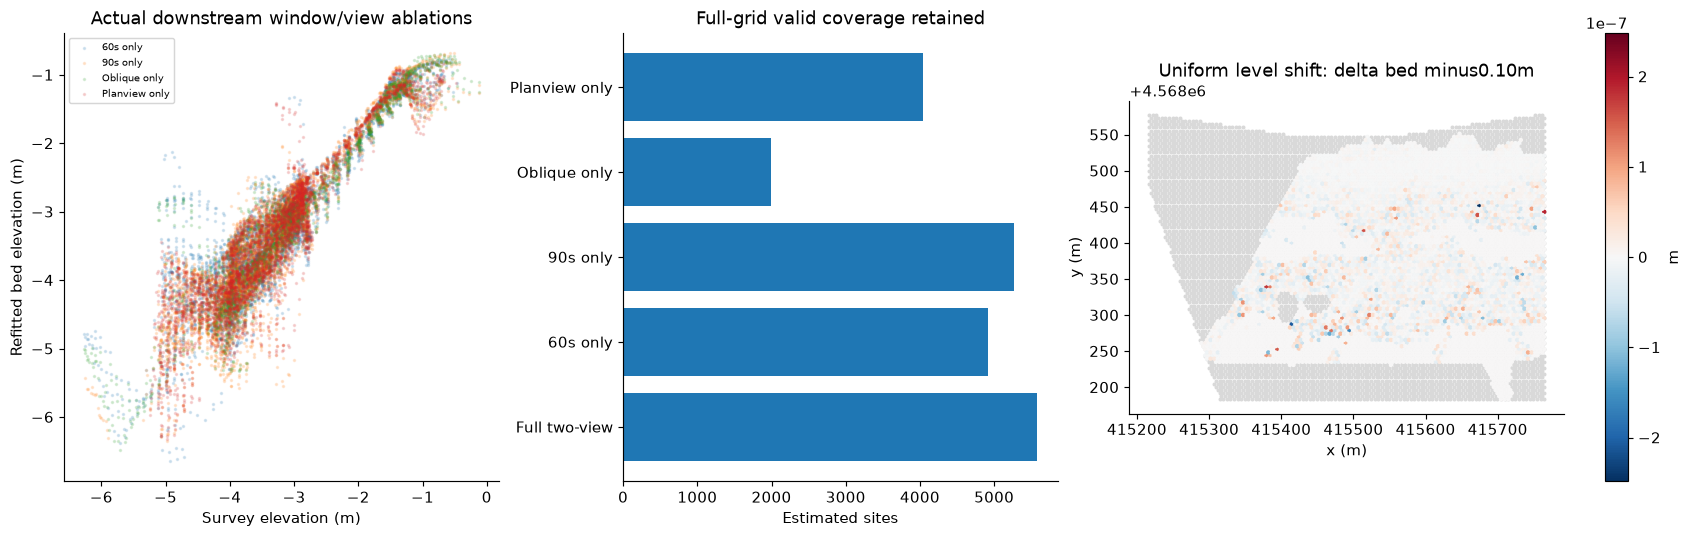

Water-level shift common sites 5577 RMS translation discrepancy(m) 1.8736325294505085e-08


In [10]:
ablations=[]
for window in [60,90]:
    fields=[f for f in diag['wave_fields'] if f['window_seconds']==window]
    observations=aggregate_wave_observations(fields)
    recovered,details=fit_bed(data['reconstruction_xy'],observations);ablations.append((f'{window}s only',recovered,details))
for record in ['oblique','planview']:
    fields=[f for f in diag['wave_fields'] if f['record']==record]
    observations=aggregate_wave_observations(fields)
    recovered,details=fit_bed(data['reconstruction_xy'],observations);ablations.append((record.title()+' only',recovered,details))
shifted={k:v.copy() for k,v in diag['observations'].items()};shifted['water_level']+=.10
shifted_submission,shifted_diag=fit_bed(data['reconstruction_xy'],shifted)
fig,axs=plt.subplots(1,3,figsize=(16,5),layout='constrained')
for name,recovered,details in ablations:
    m=recovered['validity'][0];v=recovered['reconstruction'][0];ncc,nrmse=judge.score(v[m],survey[m]);print(name,'valid=',m.sum(),'own-valid NCC=',ncc,'own-valid NRMSE=',nrmse,'interior coverage=',np.mean(m[required]),'original-support recall=',np.mean(m[original_support]))
    axs[0].scatter(survey[m],v[m],s=2,alpha=.15,label=name)
axs[0].set(title='Actual downstream window/view ablations',xlabel='Survey elevation (m)',ylabel='Refitted bed elevation (m)');axs[0].legend(fontsize=7)
names=['Full two-view']+[n for n,_,_ in ablations];counts=[valid.sum()]+[r['validity'].sum() for _,r,_ in ablations];axs[1].barh(names,counts);axs[1].set(title='Full-grid valid coverage retained',xlabel='Estimated sites')
common=valid&shifted_submission['validity'][0];change=shifted_submission['reconstruction'][0]-bed
point_map(axs[2],data['reconstruction_xy'],change-.10,'Uniform level shift: delta bed minus0.10m','m',valid=common,cmap='RdBu_r',symmetric=True);plt.show()
print('Water-level shift common sites',common.sum(),'RMS translation discrepancy(m)',np.sqrt(np.mean((change[common]-.10)**2)))


## Conclusion and execution ledger

The primary path was actively executed once from all bound optical observations. Its computed mode/wave/bed diagnostics support the explanatory figures. Stage robustness and downstream ablations were separately executed, and all archived source results are labeled as reproduced comparisons. The independent survey is the only ground truth here. Grey unsupported regions, fixed coverage, exact datum conventions and the absence of calibrated uncertainty are retained; no post-fit selection by survey error was used.

In [11]:
summary={'active_full_seconds':fresh_seconds,'stages':diag['timings'],'judge':report,'fresh_valid_sites':int(valid.sum()),'full_sites':len(valid),'modes':sum(len(r['modes']) for r in diag['records']),'qualified_wave_observations':len(diag['observations']['gamma'])}
print(json.dumps(summary,indent=2,allow_nan=False))
Path('output/notebook_measurements.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')


{
  "active_full_seconds": 810.1888201000402,
  "stages": {
    "modes_seconds": 2.9622661999892443,
    "wave_seconds": 794.6082160000224,
    "aggregation_seconds": 0.005398700013756752,
    "bed_seconds": 12.61282779998146
  },
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "interior_ncc": 0.995112649237658,
      "interior_nrmse": 0.07994553735864468,
      "all_valid_ncc": 0.9930284204194217,
      "all_valid_nrmse": 0.067696538411297,
      "required_coverage": 0.9877114870881567,
      "interior_coverage": 1.0
    },
    "thresholds": {
      "interior_ncc": {
        "comparison": ">=",
        "boundary": 0.8955139166244761
      },
      "interior_nrmse": {
        "comparison": "<=",
        "boundary": 0.08879805202146492
      },
      "all_valid_ncc": {
        "comparison": ">=",
        "boundary": 0.8933923566338204
      },
      "all_valid_nrmse": {
        "comparison": "<=",
        "boundary": 0.07642603095784656
      },
      "requ

1304